# Detecção de Fraudes e Segmentação de Clientes em Cartões de Crédito (Pipeline KDD)

Este estudo aplica a metodologia **KDD (*Knowledge Discovery in Databases*)** sobre a base exclusiva `base04_cartao_alta_dimensao.csv`, composta por registros transacionais e comportamentais de clientes de uma operadora de cartões de crédito sem rótulos pré-definidos.

O fluxo de trabalho está organizado nas cinco etapas clássicas do KDD:
1. **Seleção e Diagnóstico dos Dados**: importação da base, inspeção da dimensionalidade, tipagem das variáveis, verificação de dados nulos e remoção de identificadores sem valor analítico.
2. **Análise Exploratória de Dados (AED)**: investigação da história comportamental contada pelas variáveis de limite, consumo, canais de pagamento, tipos de lojistas e indicadores de risco (saques no crédito, compras na madrugada, estornos e alterações cadastrais).
3. **Pré-processamento**: codificação de variáveis categóricas nominais via *One-Hot Encoding*, mapeamento da matriz de correlação com eliminação de atributos colineares ($|r| > 0,90$) e remoção de outliers univariados extremos ($4,0 \times \text{IQR}$).
4. **Transformação**: padronização com `RobustScaler` e redução de dimensionalidade linear via Análise de Componentes Principais (PCA), com nova inspeção gráfica pós-tratamento.
5. **Mineração de Dados e Interpretação**: aplicação comparativa do **K-Means** como *baseline* particional, do **DBSCAN** para isolamento de anomalias e possíveis fraudes por densidade, e do **GMM (*Gaussian Mixture Models*)** para segmentação probabilística (*soft clustering*) dos perfis de consumo.

## 1. Importação das Bibliotecas

Importamos as bibliotecas de análise de dados (`pandas`, `numpy`), visualização (`matplotlib`, `seaborn`), pré-processamento e agrupamento (`scikit-learn`), além do módulo `util.py`, que armazena apenas as funções utilitárias de reuso recorrente (carregamento, diagnóstico de estrutura, plotagem padronizada de histograma com boxplot e cálculo consolidado de métricas de validação de clusters).

In [1]:
import sys
import os

sys.path.append(os.path.abspath("../src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import util

util.configure_plot_style()

## 2. Etapa de Seleção (KDD): Importação e Diagnóstico Inicial da Base

Carregamos a base `base04_cartao_alta_dimensao.csv` e verificamos suas dimensões, a quantidade de colunas, os tipos de variáveis e a presença de dados nulos.

### O que escolhemos e por que não escolhemos outra abordagem
- **Ausência de Imputação de Dados Nulos**: Todas as 37 colunas possuem exatamente 5.000 registros válidos (0 valores ausentes). Por essa razão, não aplicamos técnicas de imputação por média, mediana ou *KNN Imputer*, evitando alterar a distribuição real dos dados.
- **Remoção do Atributo `id_cliente` na Modelagem**: A coluna `id_cliente` (`C000001` a `C005000`) é apenas uma chave identificadora única de banco de dados. Mantê-la ou transformá-la em número criaria uma relação artificial baseada na ordem de cadastro.

In [2]:
raw_df = util.load_data("../data/raw/base04_cartao_alta_dimensao.csv")
util.show_info(raw_df)

Dimensoes da Base: 5000 linhas x 37 colunas
Total de Valores Ausentes (Nulos): 0

Contagem de Tipos de Variaveis:
float64    19
int64      15
object      3

Valores Nulos por Coluna:
id_cliente                          0
limite_total_credito                0
limite_utilizado_pct                0
gasto_medio_mensal_3m               0
gasto_medio_mensal_12m              0
gasto_maximo_unico                  0
qtd_transacoes_30d                  0
qtd_transacoes_90d                  0
qtd_estornos_12m                    0
valor_estornos_12m                  0
taxa_estorno_pct                    0
qtd_atrasos_12m                     0
dias_desde_ultimo_atraso            0
pct_pagamento_minimo                0
pct_pagamento_total_fatura          0
qtd_parcelamentos_12m               0
pct_compras_parceladas              0
pct_compras_online                  0
pct_compras_internacionais          0
pct_compras_madrugada               0
pct_compras_fim_de_semana           0
qtd_lojistas_distin

Exibimos o resumo estatístico (`describe`) acrescido da mediana, do intervalo interquartil (IQR) e da assimetria (*skewness*) de todas as 34 variáveis numéricas.

In [3]:
num_initial_df = raw_df.select_dtypes(include=[np.number])
summary_table = num_initial_df.describe().T
summary_table["mediana"] = num_initial_df.median()
summary_table["iqr"] = num_initial_df.quantile(0.75) - num_initial_df.quantile(0.25)
summary_table["assimetria"] = num_initial_df.skew()
summary_table[["count", "mean", "std", "min", "25%", "mediana", "75%", "max", "iqr", "assimetria"]].round(2)

,count,mean,std,min,25%,mediana,75%,max,iqr,assimetria
limite_total_credito,5000.0,10225.10,8003.63,630.75,4892.14,7887.74,12840.01,98888.34,7947.87,2.41
limite_utilizado_pct,5000.0,36.75,19.76,8.59,20.55,29.20,54.72,86.46,34.18,0.72
gasto_medio_mensal_3m,5000.0,3231.42,2463.05,652.32,1392.67,2184.01,4635.97,16450.60,3243.30,1.23
gasto_medio_mensal_12m,5000.0,3236.52,2519.38,597.05,1385.25,2173.30,4545.72,21266.03,3160.47,1.34
gasto_maximo_unico,5000.0,1545.27,1031.63,277.53,725.02,1186.15,2164.68,7407.01,1439.66,1.11
qtd_transacoes_30d,5000.0,28.28,14.70,4.00,18.00,25.00,35.00,156.00,17.00,1.48
qtd_transacoes_90d,5000.0,84.86,44.45,11.00,53.00,76.00,106.00,499.00,53.00,1.48
qtd_estornos_12m,5000.0,1.66,1.59,0.00,1.00,1.00,2.00,22.00,1.00,3.03
valor_estornos_12m,5000.0,424.25,342.38,19.17,162.70,349.61,579.95,3474.03,417.25,1.72
taxa_estorno_pct,5000.0,3.93,2.91,0.39,1.56,3.01,5.69,22.66,4.13,1.10


## 3. Análise Exploratória de Dados (AED): A História que os Dados Contam

Os 37 atributos da base descrevem quatro eixos comportamentais da operação de cartões em janelas de 30 dias, 90 dias e 12 meses:
1. **Capacidade e Uso de Crédito**: `limite_total_credito` varia de R\$ 630,75 a R\$ 98.888,34, com média de R\$ 10.225,10, mas mediana de R\$ 7.887,75 e assimetria positiva de $2,41$. Metade dos clientes utiliza até $29,2\%$ do limite disponível (`limite_utilizado_pct`), enquanto o quartil superior supera $54,7\%$.
2. **Dinâmica de Gasto e Parcelamento**: O gasto médio mensal nos últimos 3 meses (`gasto_medio_mensal_3m`, média de R\$ 3.231,42 e mediana de R\$ 2.184,01) acompanha quase perfeitamente a média de 12 meses (`gasto_medio_mensal_12m`, média de R\$ 3.236,52). O ticket médio tem mediana de R\$ 97,57, porém exibe cauda longa até R\$ 2.412,74.
3. **Sinais de Risco, Inadimplência e Fraude**: Variáveis como `qtd_saques_credito_12m` (assimetria $2,99$), `qtd_estornos_12m` (assimetria $3,03$), `pct_compras_madrugada` (assimetria $2,05$) e `qtd_alteracoes_cadastrais_12m` (assimetria $1,60$) permanecem baixas para a maior parte da carteira, mas apresentam picos extremos em subgrupos específicos — comportamento típico de invasão de conta (*account takeover*), testes de cartão clonado na madrugada ou autofinanciamento emergencial via saque no crédito.
4. **Hábito por Lojista e Canal**: Duas variáveis categóricas nominais indicam onde e como o cliente mais transaciona (`tipo_lojista_predominante` e `canal_acesso_predominante`).

Utilizamos a função reutilizável `util.plot_hist_and_box` para visualizar os histogramas e boxplots das quatro variáveis financeiras centrais.

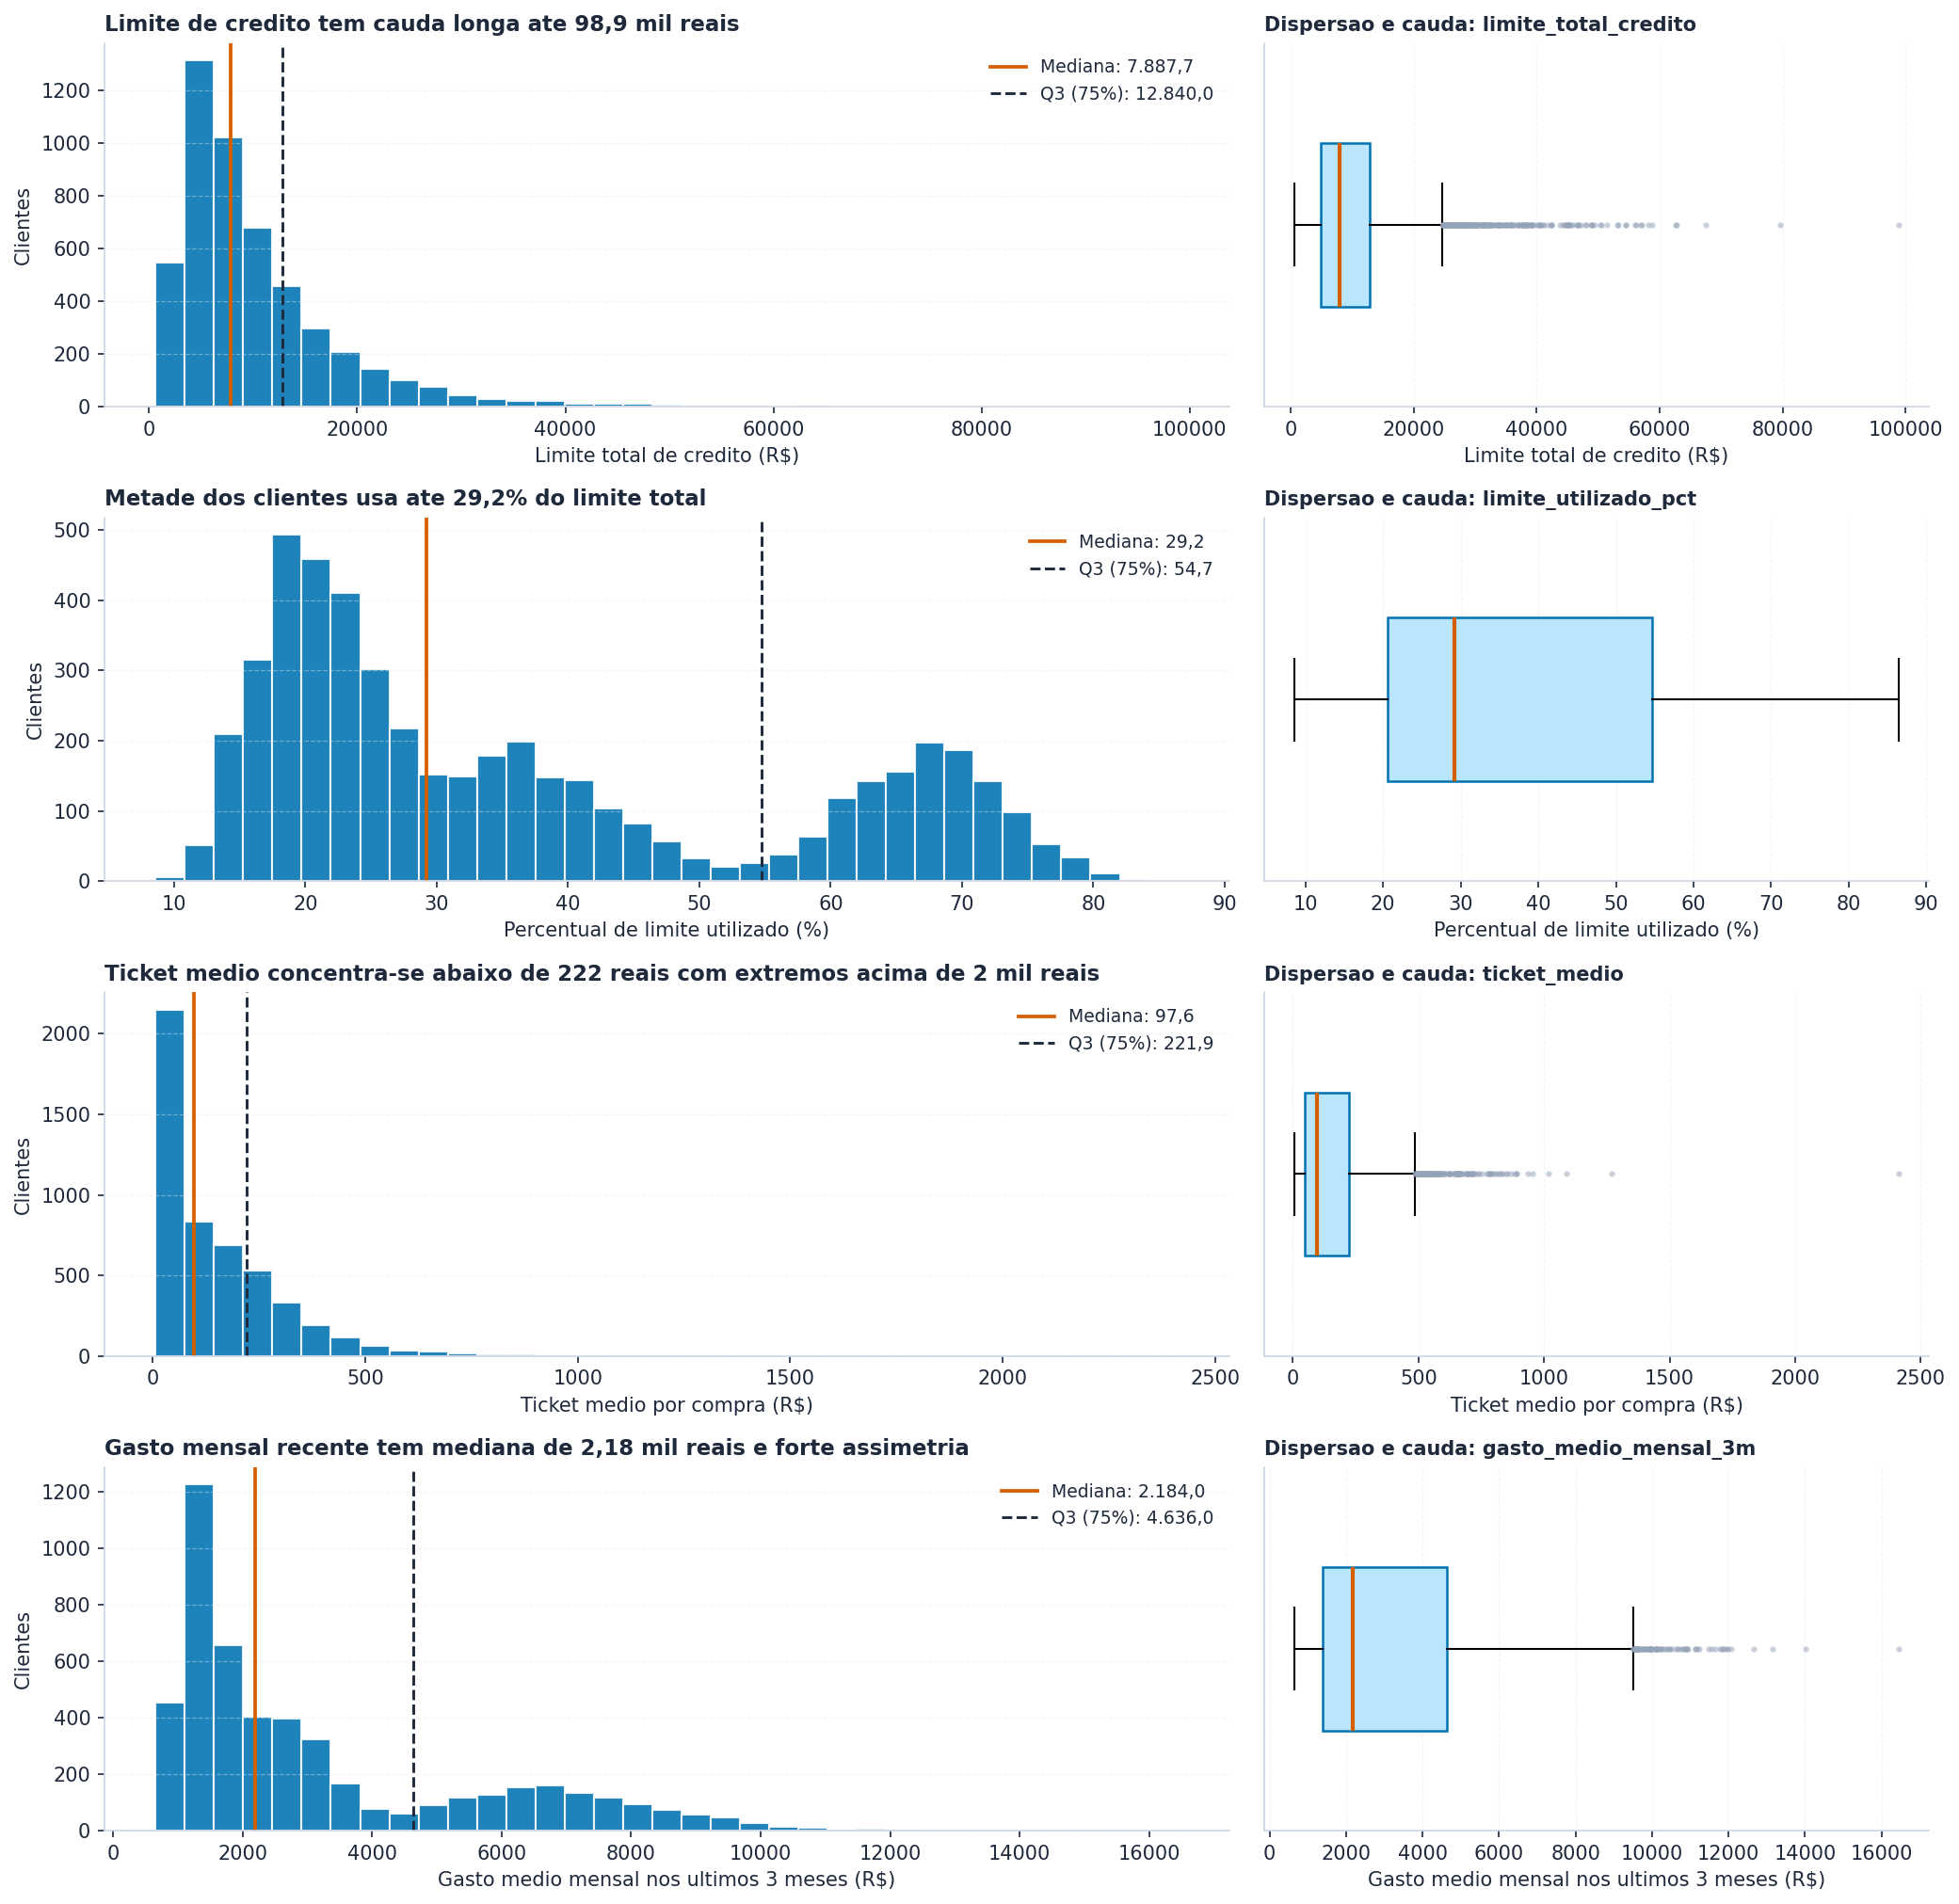

In [4]:
financial_specs = [
    ("limite_total_credito", "Limite de credito tem cauda longa ate 98,9 mil reais", "Limite total de credito (R$)"),
    ("limite_utilizado_pct", "Metade dos clientes usa ate 29,2% do limite total", "Percentual de limite utilizado (%)"),
    ("ticket_medio", "Ticket medio concentra-se abaixo de 222 reais com extremos acima de 2 mil reais", "Ticket medio por compra (R$)"),
    ("gasto_medio_mensal_3m", "Gasto mensal recente tem mediana de 2,18 mil reais e forte assimetria", "Gasto medio mensal nos ultimos 3 meses (R$)"),
]
util.plot_hist_and_box(raw_df, financial_specs, save_path="../reports/figures/fig01_eda_distribuicoes_financeiras.png")

### 3.1 Distribuição das Variáveis Categóricas (Lojista e Canal de Acesso)

Inspecionamos a frequência das categorias de `tipo_lojista_predominante` e `canal_acesso_predominante`. Três setores de consumo cotidiano (`supermercado`, `combustivel` e `restaurante`) concentram $63,5\%$ dos titulares, enquanto compras por aproximação (`contactless`, $46,3\%$) e comércio eletrônico (`web`, $24,7\%$) dominam os canais.

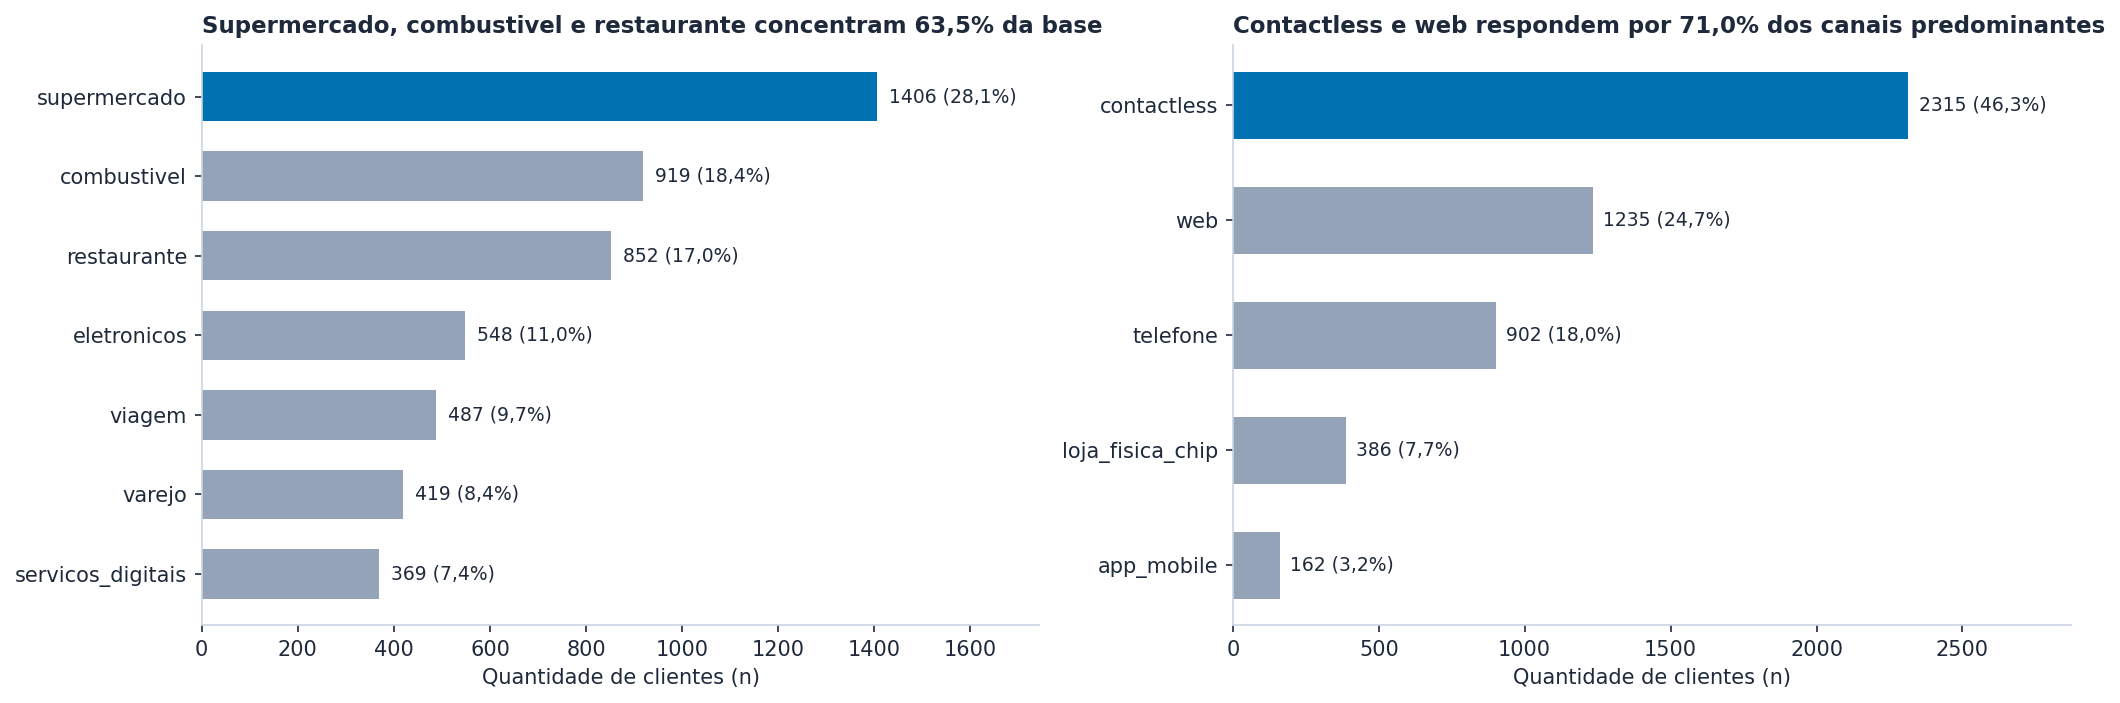

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))

lojista_counts = raw_df["tipo_lojista_predominante"].value_counts().sort_values(ascending=True)
lojista_pct = (lojista_counts / len(raw_df)) * 100
colors_loj = [util.COLOR_NEUTRAL] * (len(lojista_counts) - 1) + [util.COLOR_HIGHLIGHT]
bars1 = axs[0].barh(lojista_counts.index, lojista_counts.values, color=colors_loj, height=0.62)
axs[0].set_title("Supermercado, combustivel e restaurante concentram 63,5% da base", loc="left", fontsize=11)
axs[0].set_xlabel("Quantidade de clientes (n)")
axs[0].set_xlim(0, lojista_counts.max() * 1.24)
for bar, pct in zip(bars1, lojista_pct.values):
    w = bar.get_width()
    axs[0].text(w + 25, bar.get_y() + bar.get_height() / 2, f"{int(w)} ({pct:.1f}%)".replace(".", ","), va="center", fontsize=9)

canal_counts = raw_df["canal_acesso_predominante"].value_counts().sort_values(ascending=True)
canal_pct = (canal_counts / len(raw_df)) * 100
colors_can = [util.COLOR_NEUTRAL] * (len(canal_counts) - 1) + [util.COLOR_HIGHLIGHT]
bars2 = axs[1].barh(canal_counts.index, canal_counts.values, color=colors_can, height=0.58)
axs[1].set_title("Contactless e web respondem por 71,0% dos canais predominantes", loc="left", fontsize=11)
axs[1].set_xlabel("Quantidade de clientes (n)")
axs[1].set_xlim(0, canal_counts.max() * 1.24)
for bar, pct in zip(bars2, canal_pct.values):
    w = bar.get_width()
    axs[1].text(w + 35, bar.get_y() + bar.get_height() / 2, f"{int(w)} ({pct:.1f}%)".replace(".", ","), va="center", fontsize=9)

plt.tight_layout()
fig.savefig("../reports/figures/fig02_eda_categoricas.png")
plt.show()

### 3.2 Relação entre Limite Total, Valor Utilizado e Maturidade da Conta

O gráfico de dispersão abaixo cruza o limite total concedido com o valor efetivamente utilizado, codificando a idade da conta em meses pela cor. Observa-se uma bifurcação clara: clientes mais antigos (acima de 80 meses) detêm limites elevados mas mantêm o valor utilizado contido (abaixo de R\$ 5 mil), ao passo que um grupo de maturidade intermediária (30 a 60 meses) consome entre $60\%$ e $85\%$ do limite total.

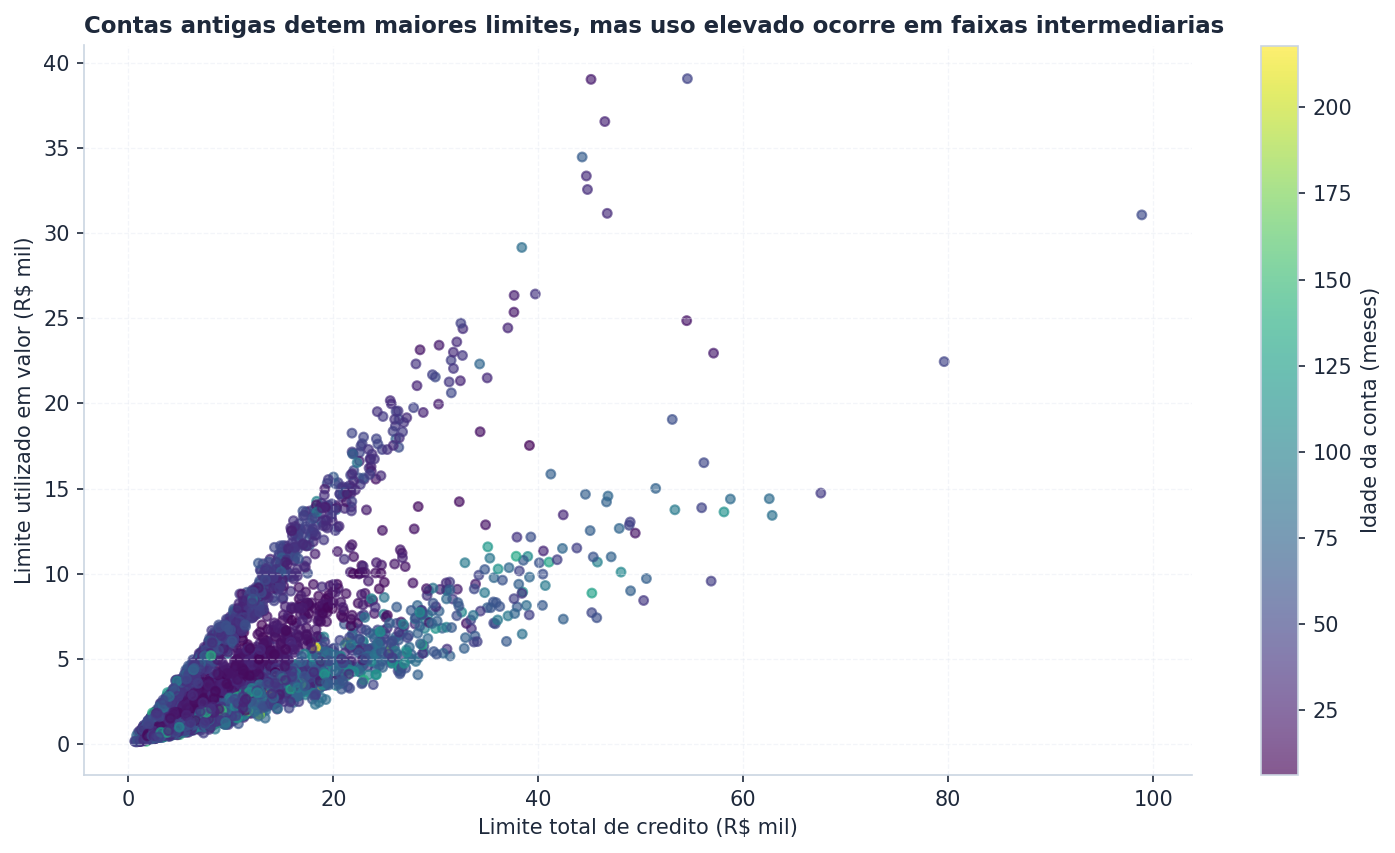

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.8))
scatter = ax.scatter(
    raw_df["limite_total_credito"] / 1000.0,
    raw_df["limite_utilizado_valor"] / 1000.0,
    c=raw_df["idade_conta_meses"],
    cmap="viridis",
    alpha=0.65,
    s=18,
)
cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label("Idade da conta (meses)")
ax.set_title("Contas antigas detem maiores limites, mas uso elevado ocorre em faixas intermediarias", loc="left", fontsize=11)
ax.set_xlabel("Limite total de credito (R$ mil)")
ax.set_ylabel("Limite utilizado em valor (R$ mil)")
ax.grid(True, alpha=0.4)
plt.tight_layout()
fig.savefig("../reports/figures/fig03_eda_dispersao_limite.png")
plt.show()